# 02 · H2: How much of the drop is gold and energy?

**Hypothesis H2.** Excluding gold and energy, the decline in the US share is much smaller than the headline decline.

**Frozen rule.** Confirmed if the decline without gold and energy is at most 50% of the headline decline (in percentage points). Rejected if above 50%.

**Method in plain words.** We compute the change in the US share three ways: all goods, without gold, and without gold and energy. The differences between them are the gold and energy effects. Because the result depends on which item is removed first, both orders are computed and their average is reported.

Gold = HS 7108; energy = HS 27. All numbers come from `mart_waterfall`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis
from src.common import load_settings

pd.set_option("display.float_format", "{:,.4f}".format)
con = analysis.connect()
start, end = analysis.tariff_window(con)
print(f"Tariff period (latest 12 months): {start} to {end}")

Tariff period (latest 12 months): Oct 2025 to Sep 2026


## Waterfall components (percentage points)

In [2]:
rows = []
for baseline, label in analysis.BASELINES.items():
    w = analysis.h2(con, baseline)
    rows.append({
        "baseline": label,
        "US share, baseline (%)": w["s_base_pct"], "US share, latest (%)": w["s_tariff_pct"],
        "total change (pp)": w["total"],
        "gold (pp, avg)": w["gold"], "gold, gold first": w["gold_range"][0], "gold, energy first": w["gold_range"][1],
        "energy (pp, avg)": w["energy"], "energy, gold first": w["energy_range"][0], "energy, energy first": w["energy_range"][1],
        "everything else (pp)": w["rest"],
    })
pd.DataFrame(rows)

,baseline,"US share, baseline (%)","US share, latest (%)",total change (pp),"gold (pp, avg)","gold, gold first","gold, energy first","energy (pp, avg)","energy, gold first","energy, energy first",everything else (pp)
0,2022–2024,76.2003,67.7638,-8.4366,-4.7038,-4.0525,-5.3551,-0.3969,-1.0482,0.2544,-3.3359
1,2023–2024,76.4005,67.7638,-8.6367,-4.7021,-4.0285,-5.3757,0.2518,-0.4219,0.9254,-4.1864


## Verdict against the frozen threshold

In [3]:
rows = []
for baseline, label in analysis.BASELINES.items():
    w = analysis.h2(con, baseline)
    rows.append({"baseline": label, "headline change (pp)": w["total"],
                 "change without gold and energy (pp)": w["rest"],
                 "ratio (without / headline)": w["ratio"], "threshold": w["limit"],
                 "H2 verdict": w["verdict"]})
h2_table = pd.DataFrame(rows)
display(h2_table)
for r in h2_table.itertuples():
    print(f"Baseline {r.baseline}: H2 {r._6.upper()}. Without gold and energy the US share changed "
          f"{r._3:.2f} pp vs {r._2:.2f} pp for all goods, a ratio of {r._4:.1%} (threshold {r.threshold:.0%}).")
print("Verdict is the same for both baselines." if h2_table["H2 verdict"].nunique() == 1
      else "Verdict changes with the baseline.")

,baseline,headline change (pp),change without gold and energy (pp),ratio (without / headline),threshold,H2 verdict
0,2022–2024,-8.4366,-3.3359,0.3954,0.5000,confirmed
1,2023–2024,-8.6367,-4.1864,0.4847,0.5000,confirmed


Baseline 2022–2024: H2 CONFIRMED. Without gold and energy the US share changed -3.34 pp vs -8.44 pp for all goods, a ratio of 39.5% (threshold 50%).
Baseline 2023–2024: H2 CONFIRMED. Without gold and energy the US share changed -4.19 pp vs -8.64 pp for all goods, a ratio of 48.5% (threshold 50%).
Verdict is the same for both baselines.


## Charts

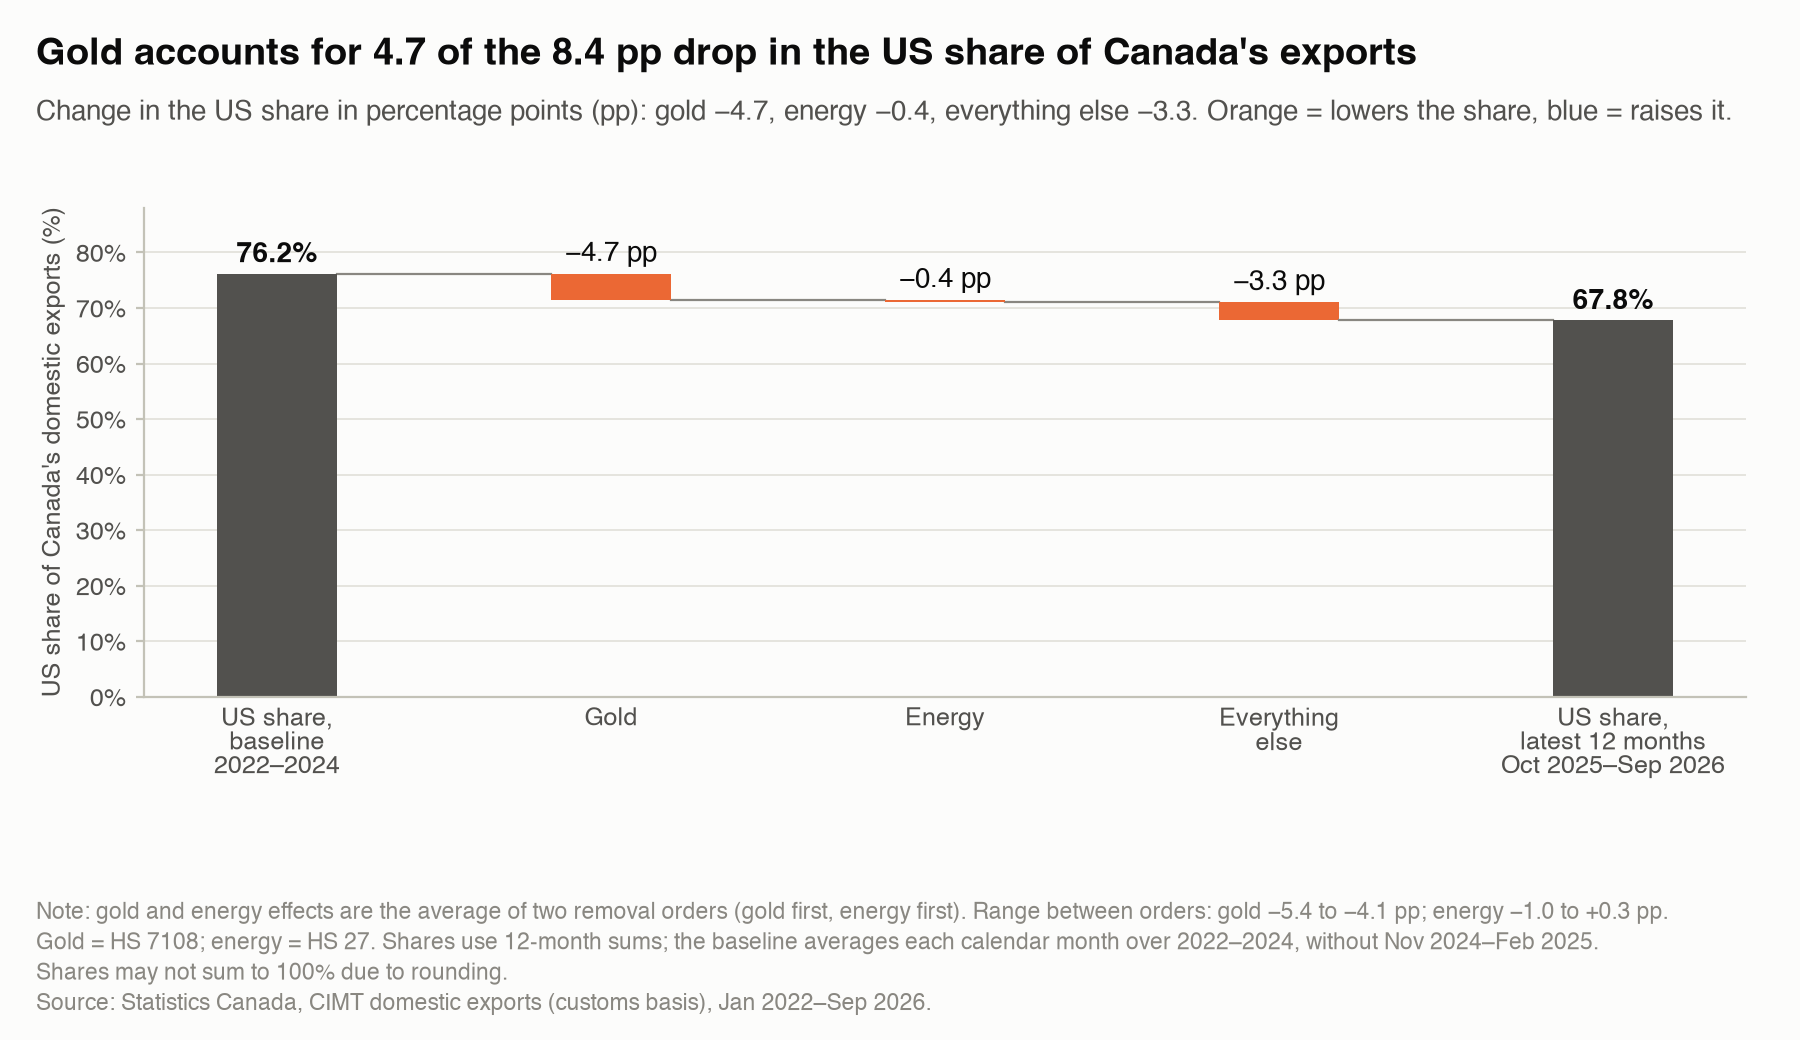

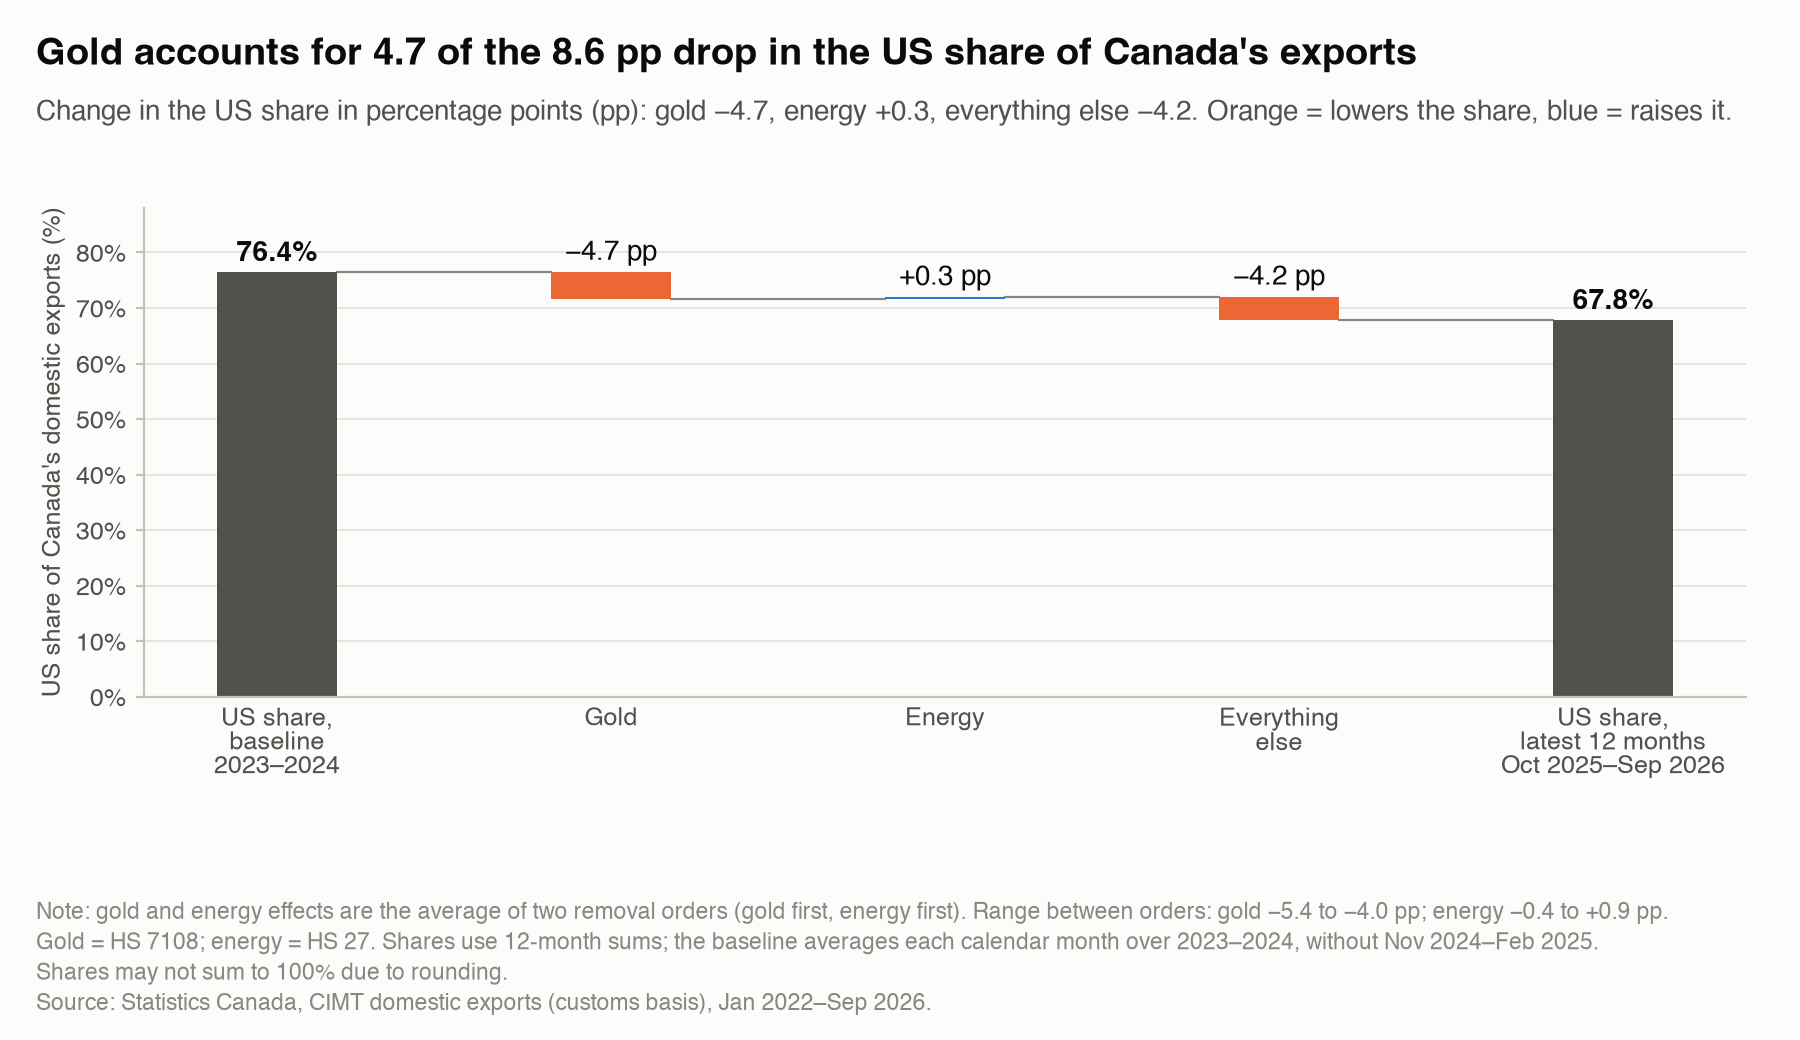

In [4]:
display(Image(filename=str(ROOT / "figures" / "h2_waterfall.png"), width=900))
display(Image(filename=str(ROOT / "figures" / "h2_waterfall_sensitivity.png"), width=900))

## M4 · Price or volume? Gold and crude oil

The change in yearly export value is split into a **price effect** and a **volume effect** with the midpoint formula: ΔV = ΔP·Q̄ + ΔQ·P̄. P is the customs unit value (value divided by quantity: grams for gold, cubic metres for crude), Q̄ and P̄ are the averages of the baseline and the latest 12 months. The two effects add up exactly to the change in value. Numbers come from `mart_price_volume`; values in CAD billions.

In [5]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for commodity in ["gold", "crude"]:
        for destination in ["Non-US", "United States"]:
            r = analysis.price_volume(con, baseline, commodity, destination)
            rows.append({
                "baseline": label, "commodity": commodity, "destination": destination,
                "value, baseline": r["v_base"] / 1e9, "value, latest": r["v_tariff"] / 1e9,
                "change": r["d_value"] / 1e9, "price effect": r["price_effect"] / 1e9,
                "volume effect": r["volume_effect"] / 1e9,
                "unit value change (%)": 100 * r["p_growth"], "quantity change (%)": 100 * r["q_growth"],
            })
pd.DataFrame(rows)

,baseline,commodity,destination,"value, baseline","value, latest",change,price effect,volume effect,unit value change (%),quantity change (%)
0,2022–2024,gold,Non-US,22.0591,67.7017,45.6426,35.0432,10.5994,139.1463,28.3360
1,2022–2024,gold,United States,6.3875,4.5744,-1.8131,4.6663,-6.4794,108.7927,-65.7002
2,2022–2024,crude,Non-US,4.5451,20.5225,15.9774,0.5092,15.4682,4.2014,333.3249
3,2022–2024,crude,United States,141.7962,137.5216,-4.2746,-4.2278,-0.0468,-2.9821,-0.0335
4,2023–2024,gold,Non-US,22.5695,67.7017,45.1321,31.9549,13.1773,119.7215,36.5226
5,2023–2024,gold,United States,8.3341,4.5744,-3.7597,5.4492,-9.2089,102.9290,-72.9521
6,2023–2024,crude,Non-US,4.7946,20.5225,15.7279,1.2633,14.4646,10.8390,286.1759
7,2023–2024,crude,United States,136.7787,137.5216,0.7429,3.5631,-2.8202,2.6318,-2.0351


Gold to other countries (baseline 2022–2024): value +45.6 bn CAD a year; price effect +35.0 bn (77%), volume effect +10.6 bn.


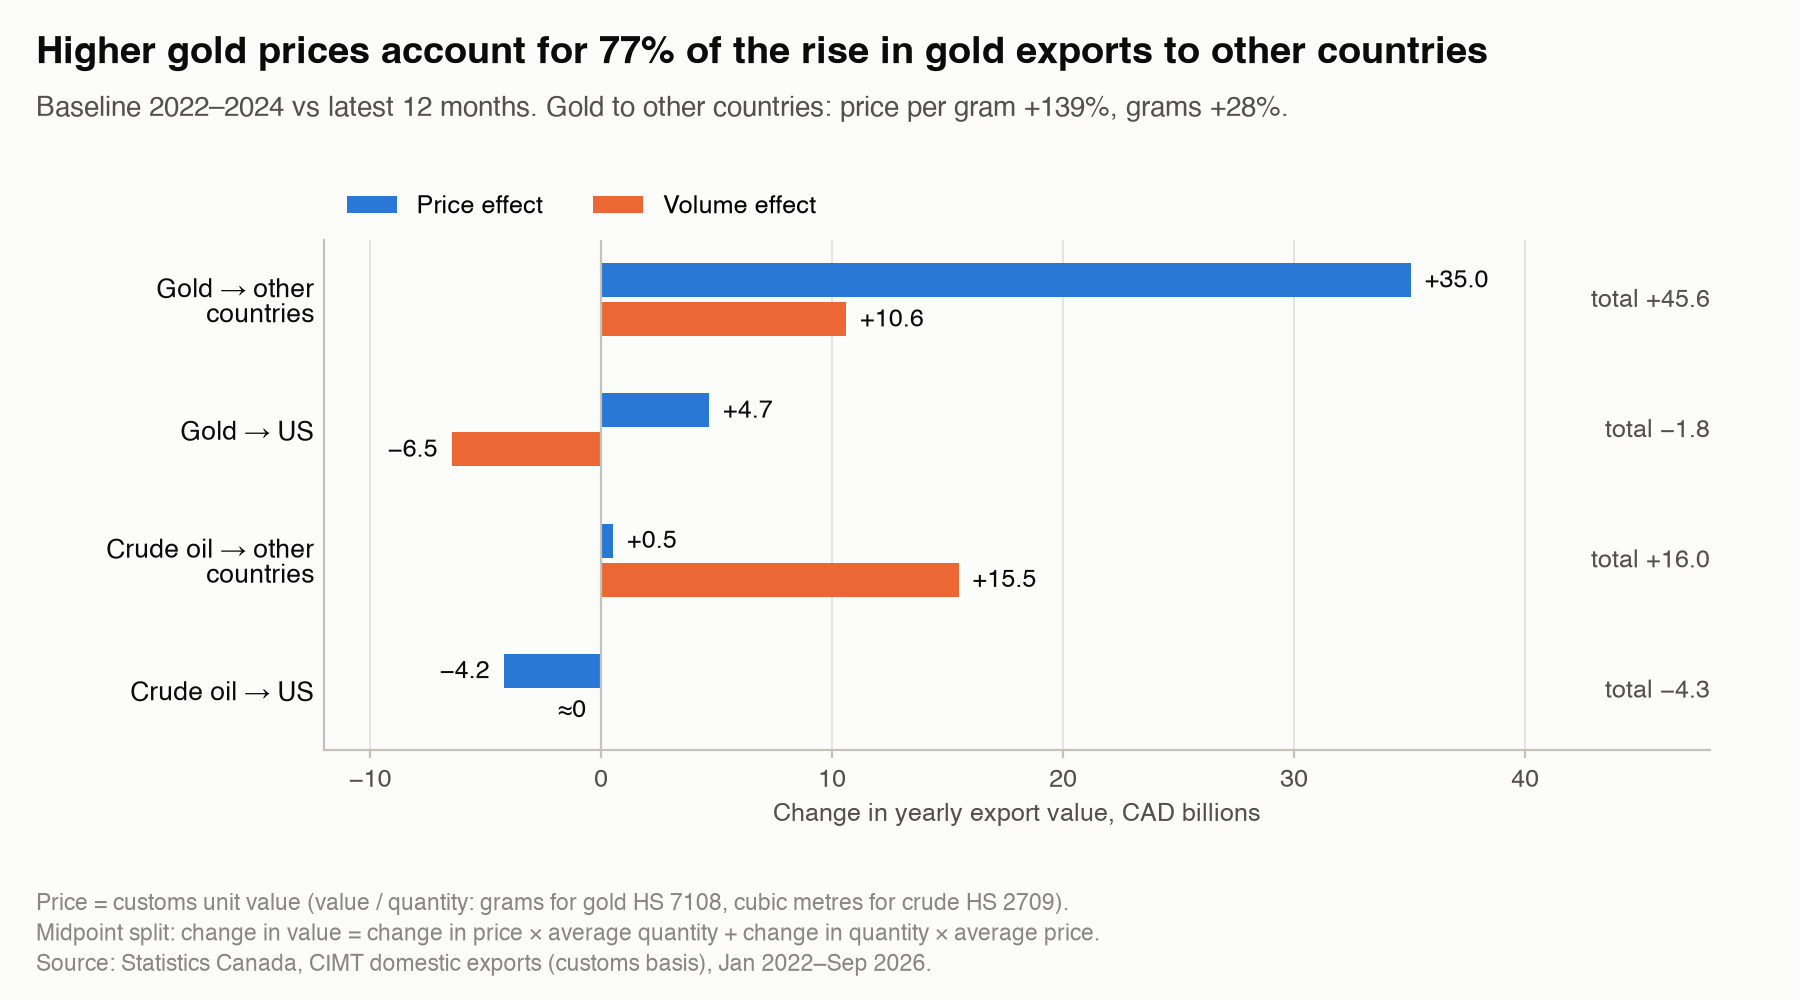

In [6]:
g = analysis.price_volume(con, "primary", "gold", "Non-US")
print(f"Gold to other countries (baseline 2022–2024): value {g['d_value'] / 1e9:+.1f} bn CAD a year; "
      f"price effect {g['price_effect'] / 1e9:+.1f} bn ({g['price_share']:.0%}), "
      f"volume effect {g['volume_effect'] / 1e9:+.1f} bn.")
display(Image(filename=str(ROOT / "figures" / "m4_price_volume.png"), width=900))

**Unit value check.** How close is the customs unit value to the World Bank benchmark price (converted to CAD per gram or per cubic metre)? Validation check V3 requires gold to stay within ±10% each month. Crude is shown for information; only its change over time is used in the split above.

In [7]:
gaps = con.execute("""
    select commodity,
           median(unit_value_cad / benchmark_cad_per_unit - 1) as median_gap,
           min(unit_value_cad / benchmark_cad_per_unit - 1) as min_gap,
           max(unit_value_cad / benchmark_cad_per_unit - 1) as max_gap
    from mart_price_volume_monthly
    where destination = 'All destinations'
    group by commodity order by commodity""").df()
gaps

,commodity,median_gap,min_gap,max_gap
0,crude,-0.1052,-0.3257,0.0571
1,gold,-0.0286,-0.1161,0.0420


## Reading

- Gold is associated with the largest single part of the drop in the US share, and most of the rise in gold exports to other countries is a price effect, not more gold shipped. Energy adds little on average, and its sign depends on the removal order.
- With the 2023–2024 baseline the ratio is closer to the 50% threshold, so the H2 result is less comfortable there, though the verdict is the same.
- This is a description of the data. It does not show that tariffs caused the change.